In [215]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns


from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn import tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler, OrdinalEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import (accuracy_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings('ignore')

#decsion tree clasfi target = attack
#linear regression target = avg_packet_size

In [216]:
df = pd.read_csv('Dataset2_odd_students.csv')

print('─' * 50)
print(f'  Rows    : {df.shape[0]}')
print(f'  Columns : {df.shape[1]}')
print('─' * 50)
print('\nColumn names and types:')
print(df.dtypes)
print('\nFirst 5 rows:')
df.head()


──────────────────────────────────────────────────
  Rows    : 6000
  Columns : 19
──────────────────────────────────────────────────

Column names and types:
packet_session_id        str
protocol                 str
device_type              str
vpn_status               str
region                   str
login_attempts         int64
failed_logins          int64
bytes_sent           float64
bytes_received       float64
packet_rate          float64
connection_count       int64
tcp_flags                str
port_number            int64
session_retries        int64
signal_strength      float64
privilege_level          str
anomaly_score        float64
avg_packet_size      float64
attack_category          str
dtype: object

First 5 rows:


,packet_session_id,protocol,device_type,vpn_status,region,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,tcp_flags,port_number,session_retries,signal_strength,privilege_level,anomaly_score,avg_packet_size,attack_category
0,P000000,TCP,Workstation,On,APAC,0,6,3735.701997,7083.530344,184.514770,7,FIN,3389,0,-71.345111,user,0.117355,332.602010,Benign
1,P000001,TCP,Workstation,Off,EU,1,2,6140.866808,4382.336675,155.062604,5,ACK,110,1,-44.351883,user,0.238888,314.553416,Benign
2,P000002,TCP,Workstation,Off,US,3,0,4714.244672,6979.428832,125.959250,4,FIN,80,0,-64.475005,user,0.123961,266.942545,Benign
3,P000003,UDP,Server,Off,APAC,2,0,2987.854450,2715.307765,88.444309,3,FIN,110,1,-48.033202,guest,0.462781,259.362639,BruteForce
4,P000004,UDP,IoT,Off,US,1,5,5021.324823,4858.666310,153.385483,2,SYN-ACK,110,2,-65.320352,user,0.185527,293.294721,BruteForce


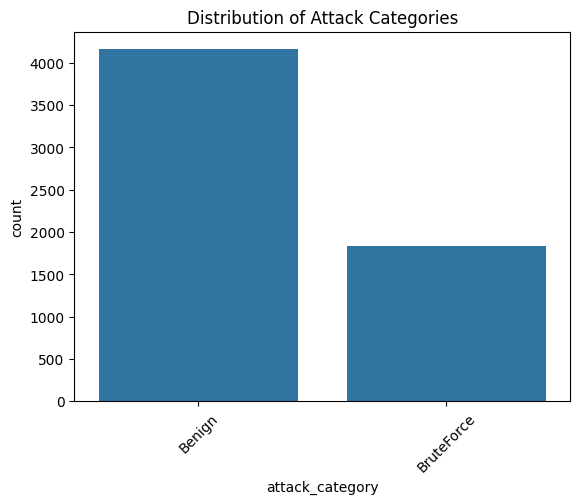

In [217]:
#this plots the Distribution of attacks 

sns.countplot(data=df, x='attack_category')
plt.title('Distribution of Attack Categories')
plt.xticks(rotation=45)
plt.show()


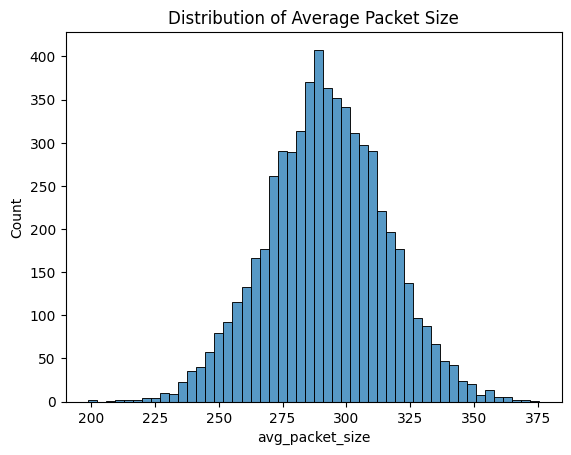

In [218]:
sns.histplot(df['avg_packet_size'], bins=50)
plt.title('Distribution of Average Packet Size')
plt.show()

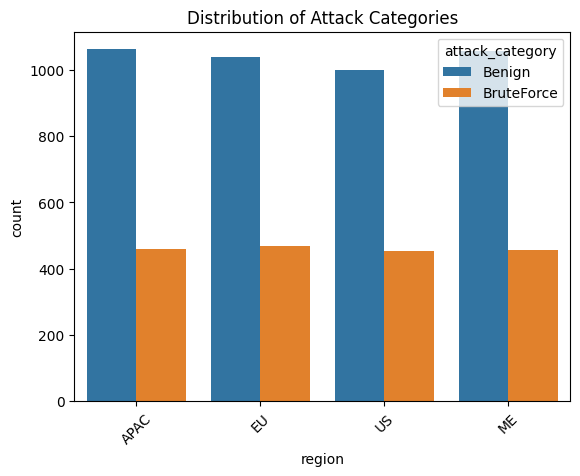

In [219]:
sns.countplot(data=df, x='region',hue='attack_category')
plt.title('Distribution of Attack Categories')
plt.xticks(rotation=45)
plt.show()



In [220]:
#copy the df to work on a new one
df_clean = df.copy()
# Combines anomaly score and login failure rate into one risk indicator



#check for missing values

print('Missing values per column:')
missing = df.isnull().sum()
pct     = (missing / len(df) * 100).round(1)
print(pd.DataFrame({'Count': missing, '%': pct}))
print()


Missing values per column:
                   Count    %
packet_session_id      0  0.0
protocol             420  7.0
device_type            0  0.0
vpn_status             0  0.0
region                 0  0.0
login_attempts         0  0.0
failed_logins          0  0.0
bytes_sent             0  0.0
bytes_received       420  7.0
packet_rate            0  0.0
connection_count       0  0.0
tcp_flags              0  0.0
port_number            0  0.0
session_retries        0  0.0
signal_strength      420  7.0
privilege_level        0  0.0
anomaly_score          0  0.0
avg_packet_size        0  0.0
attack_category        0  0.0



In [221]:
#fill missing values of the numerical data with mean since its between 5-40% of missing value

#replace the missing data for the string with mode
df_clean["protocol"] = df_clean["protocol"].fillna(df_clean["protocol"].mode()[0])


df_clean["bytes_received"] = df_clean["bytes_received"].fillna(df_clean["bytes_received"].mean())
df_clean["signal_strength"] = df_clean["signal_strength"].fillna(df_clean["signal_strength"].mean())


df_clean['login_failure_rate'] = df_clean['failed_logins'] / (df_clean['login_attempts'] + 1)
df_clean['session_suspicion_score'] = (df_clean['anomaly_score'] * 0.6) + (df_clean['login_failure_rate'] * 0.4)

mean_packet = df_clean['avg_packet_size'].mean()
std_packet = df_clean['avg_packet_size'].std()
df_clean['packet_size_anomaly'] = (df_clean['avg_packet_size'] - mean_packet) / std_packet


In [222]:
#check for missing values for clean version
print('Missing values per column:')
missing = df_clean.isnull().sum()
pct     = (missing / len(df) * 100).round(1)
print(pd.DataFrame({'Count': missing, '%': pct}))
print()

Missing values per column:
                         Count    %
packet_session_id            0  0.0
protocol                     0  0.0
device_type                  0  0.0
vpn_status                   0  0.0
region                       0  0.0
login_attempts               0  0.0
failed_logins                0  0.0
bytes_sent                   0  0.0
bytes_received               0  0.0
packet_rate                  0  0.0
connection_count             0  0.0
tcp_flags                    0  0.0
port_number                  0  0.0
session_retries              0  0.0
signal_strength              0  0.0
privilege_level              0  0.0
anomaly_score                0  0.0
avg_packet_size              0  0.0
attack_category              0  0.0
login_failure_rate           0  0.0
session_suspicion_score      0  0.0
packet_size_anomaly          0  0.0



<Axes: xlabel='attack_category'>

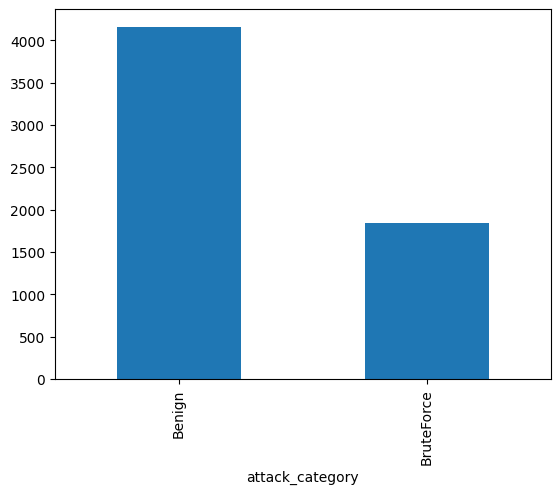

In [223]:
Target = "attack_category"
df[Target].value_counts(normalize=True)*100
df[Target].value_counts().plot(kind='bar')


In [224]:
df_model = df_clean.copy()

df_model = df_model.drop(columns=['packet_session_id'])

le = LabelEncoder()
cat_cols = df_model.select_dtypes(include='object').columns

for col in cat_cols:
    df_model[col] = le.fit_transform(df_model[col])

#drops the target coloums and split them
X = df_model.drop(columns=['attack_category', 'avg_packet_size'])

y_class = df_model['attack_category']  # Decision Tree target
y_reg = df_model['avg_packet_size']    # Linear Regression target

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X, y_class, test_size=0.2, random_state=42)

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X, y_reg, test_size=0.2, random_state=42)



In [225]:
print(df_model.dtypes)

protocol                     int64
device_type                  int64
vpn_status                   int64
region                       int64
login_attempts               int64
failed_logins                int64
bytes_sent                 float64
bytes_received             float64
packet_rate                float64
connection_count             int64
tcp_flags                    int64
port_number                  int64
session_retries              int64
signal_strength            float64
privilege_level              int64
anomaly_score              float64
avg_packet_size            float64
attack_category              int64
login_failure_rate         float64
session_suspicion_score    float64
packet_size_anomaly        float64
dtype: object


In [226]:
#scale for the linear regression
coll = X_train_reg.columns
scaler = StandardScaler()
X_train_scaled_reg = scaler.fit_transform(X_train_reg)
X_test_scaled_reg  = scaler.transform(X_test_reg)

before = pd.DataFrame(X_train_reg, columns=coll).describe().loc[['mean', 'std']].round(1)
after  = pd.DataFrame(X_train_scaled_reg, columns=coll).describe().loc[['mean', 'std']].round(3)

print('BEFORE scaling (mean / std):')
print(before)
print()
print('AFTER scaling (mean / std):')
print(after)
print()


BEFORE scaling (mean / std):
      protocol  device_type  vpn_status  region  login_attempts  \
mean       1.6          1.5         0.3     1.5             2.0   
std        1.1          1.1         0.5     1.1             1.4   

      failed_logins  bytes_sent  bytes_received  packet_rate  \
mean            1.0      5280.0          6029.7        125.2   
std             1.0      3365.6          1933.7         65.7   

      connection_count  tcp_flags  port_number  session_retries  \
mean               5.0        1.5        466.8              1.0   
std                2.2        1.1       1026.0              1.0   

      signal_strength  privilege_level  anomaly_score  login_failure_rate  \
mean            -60.0              1.5            0.3                 0.4   
std               9.6              0.8            0.2                 0.5   

      session_suspicion_score  packet_size_anomaly  
mean                      0.3                 -0.0  
std                       0.2       

Accuracy: 0.7041666666666667
              precision    recall  f1-score   support

           0       0.71      1.00      0.83       847
           1       0.00      0.00      0.00       353

    accuracy                           0.70      1200
   macro avg       0.35      0.50      0.41      1200
weighted avg       0.50      0.70      0.58      1200



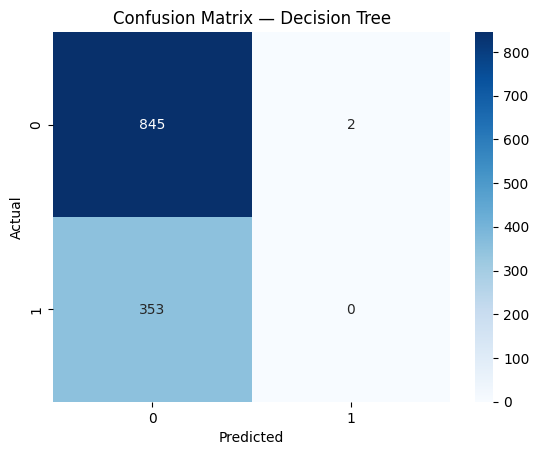

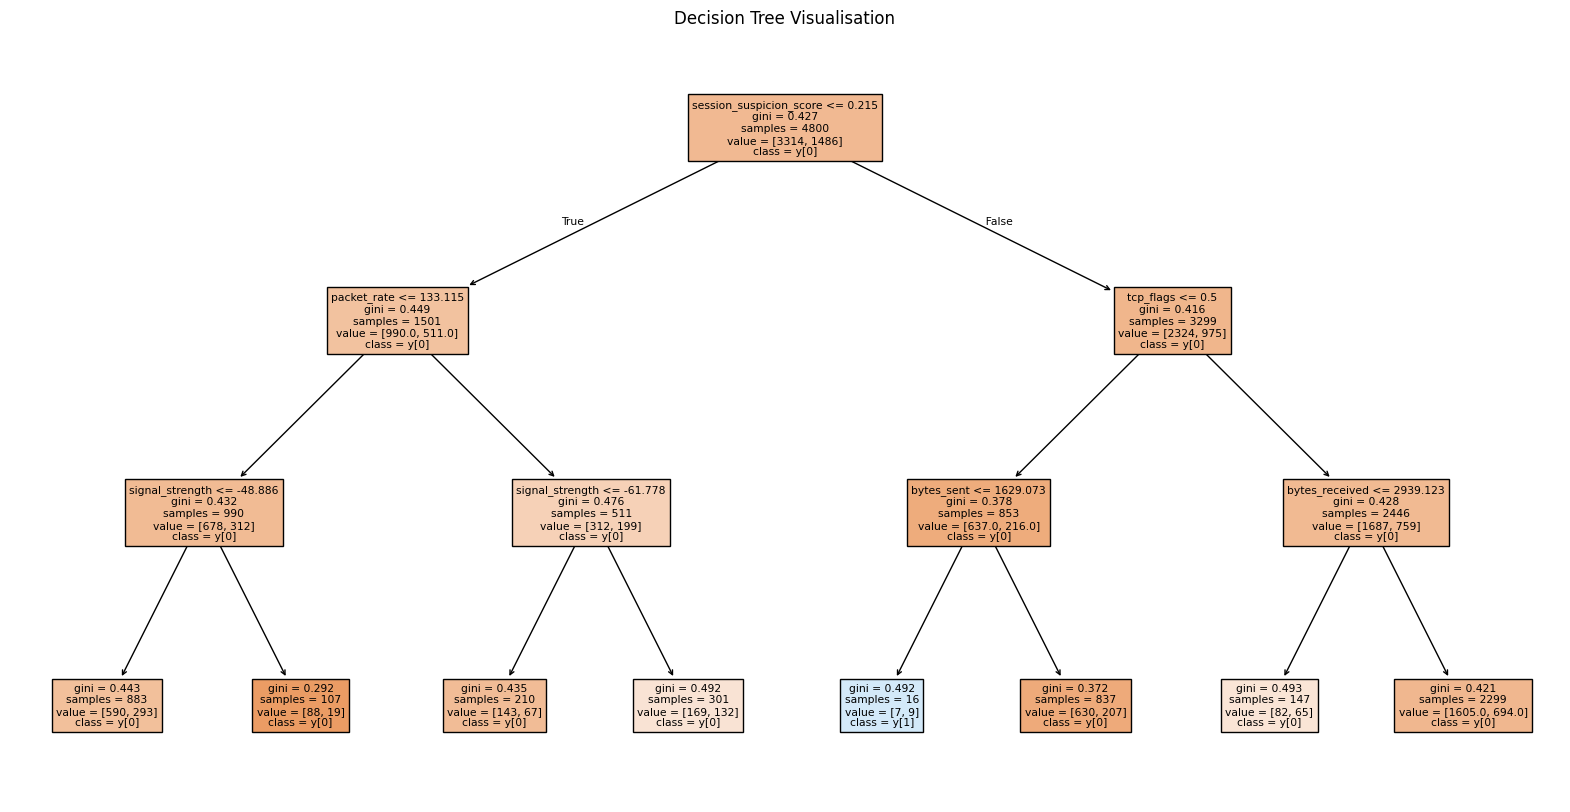

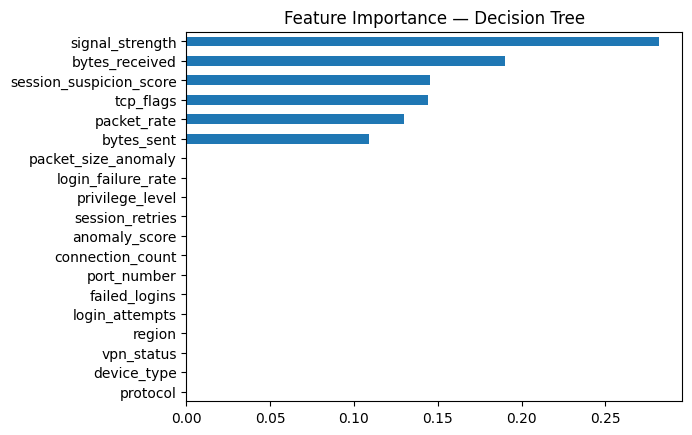

In [227]:
dt_baseline  = DecisionTreeClassifier(random_state=42, max_depth=3)
dt_baseline .fit(X_train_class, y_train_class)
#not balanced so results are way off, focusing too much on one area compared to rest
y_pred_baseline  = dt_baseline.predict(X_test_class)
print("Accuracy:", accuracy_score(y_test_class, y_pred_baseline))
print(classification_report(y_test_class, y_pred_baseline))
sns.heatmap(confusion_matrix(y_test_class, y_pred_baseline), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix — Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


plt.figure(figsize=(20,10))
plot_tree(dt_baseline, feature_names=X.columns, class_names=True, filled=True, max_depth=3)
plt.title('Decision Tree Visualisation')
plt.show()
importances = pd.Series(dt_baseline.feature_importances_, index=X.columns)
importances.sort_values().plot(kind='barh')
plt.title('Feature Importance — Decision Tree')
plt.show()

Accuracy: 0.4083333333333333
              precision    recall  f1-score   support

           0       0.68      0.31      0.42       847
           1       0.28      0.65      0.39       353

    accuracy                           0.41      1200
   macro avg       0.48      0.48      0.41      1200
weighted avg       0.56      0.41      0.41      1200



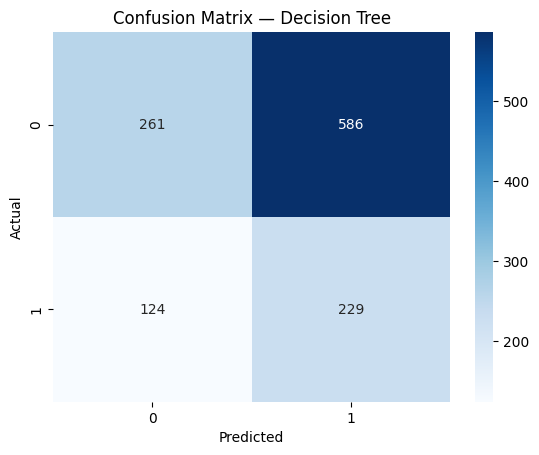

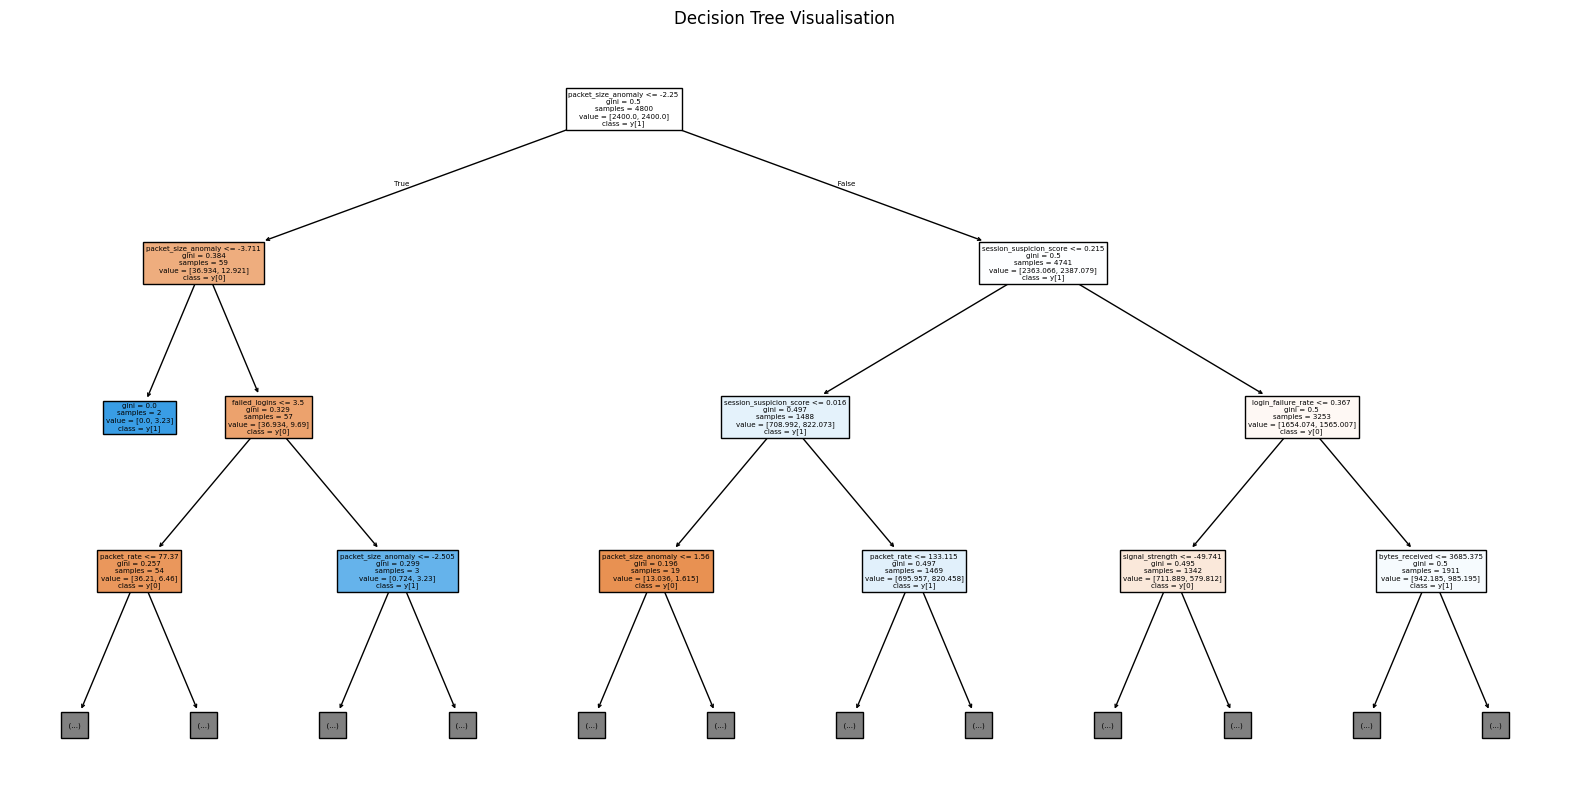

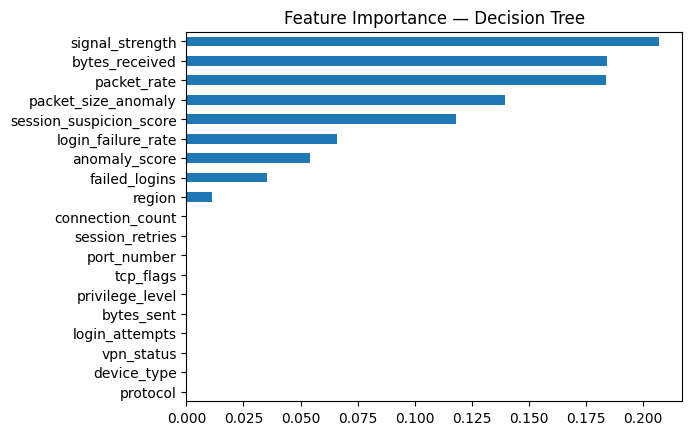

Accuracy: 0.7041666666666667
              precision    recall  f1-score   support

           0       0.71      1.00      0.83       847
           1       0.00      0.00      0.00       353

    accuracy                           0.70      1200
   macro avg       0.35      0.50      0.41      1200
weighted avg       0.50      0.70      0.58      1200



In [228]:
dt_improved = DecisionTreeClassifier(random_state=42, max_depth=5, class_weight='balanced')
dt_improved.fit(X_train_class, y_train_class)
#not balanced so results are way off, focusing too much on one area compared to rest
y_pred_improved = dt_improved.predict(X_test_class)
print("Accuracy:", accuracy_score(y_test_class, y_pred_improved))
print(classification_report(y_test_class, y_pred_improved))
sns.heatmap(confusion_matrix(y_test_class, y_pred_improved), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix — Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


plt.figure(figsize=(20,10))
plot_tree(dt_improved, feature_names=X.columns, class_names=True, filled=True, max_depth=3)
plt.title('Decision Tree Visualisation')
plt.show()
importances = pd.Series(dt_improved.feature_importances_, index=X.columns)
importances.sort_values().plot(kind='barh')
plt.title('Feature Importance — Decision Tree')
plt.show()


print("Accuracy:", accuracy_score(y_test_class, y_pred_baseline))
print(classification_report(y_test_class, y_pred_baseline))

Accuracy: 0.7041666666666667
              precision    recall  f1-score   support

           0       0.71      1.00      0.83       847
           1       0.00      0.00      0.00       353

    accuracy                           0.70      1200
   macro avg       0.35      0.50      0.41      1200
weighted avg       0.50      0.70      0.58      1200



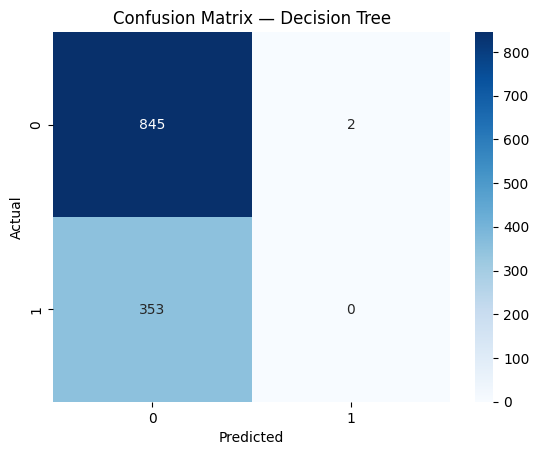

Accuracy: 0.4083333333333333
              precision    recall  f1-score   support

           0       0.68      0.31      0.42       847
           1       0.28      0.65      0.39       353

    accuracy                           0.41      1200
   macro avg       0.48      0.48      0.41      1200
weighted avg       0.56      0.41      0.41      1200



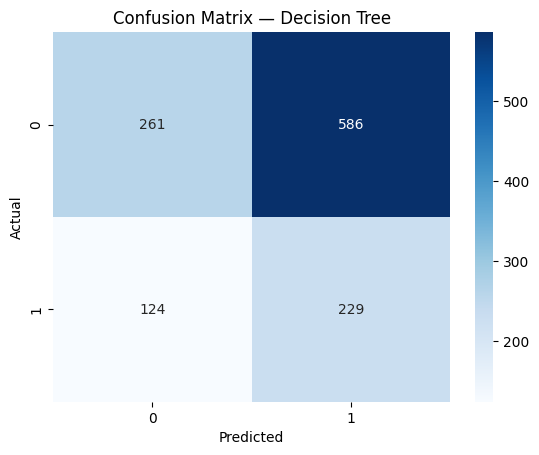

In [ ]:
y_pred_baseline  = dt_baseline.predict(X_test_class)
sns.heatmap(confusion_matrix(y_test_class, y_pred_baseline), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix — Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

y_pred_improved = dt_improved.predict(X_test_class)
sns.heatmap(confusion_matrix(y_test_class, y_pred_improved), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix — Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [229]:
print(f"Baseline Accuracy:  {accuracy_score(y_test_class, y_pred_baseline):.4f}")
print(f"Improved Accuracy:  {accuracy_score(y_test_class, y_pred_improved):.4f}")

Baseline Accuracy:  0.7042
Improved Accuracy:  0.4083


       login_attempts  failed_logins    bytes_sent  bytes_received  \
count     6000.000000     6000.00000   6000.000000     6000.000000   
mean         1.986167        1.01300   5244.930668     6030.812597   
std          1.403913        1.00565   3148.811236     1952.797247   
min          0.000000        0.00000    100.000000      100.000000   
25%          1.000000        0.00000   3985.123437     4815.093044   
50%          2.000000        1.00000   4971.300665     6030.812597   
75%          3.000000        2.00000   6017.944743     7299.204864   
max          8.000000        6.00000  53602.250239    14261.024735   

       packet_rate  connection_count  port_number  session_retries  \
count  6000.000000       6000.000000  6000.000000      6000.000000   
mean    125.406064          5.007500   464.325667         0.990000   
std      66.673500          2.231802  1022.536272         0.987453   
min      10.000000          0.000000    21.000000         0.000000   
25%      99.429233 

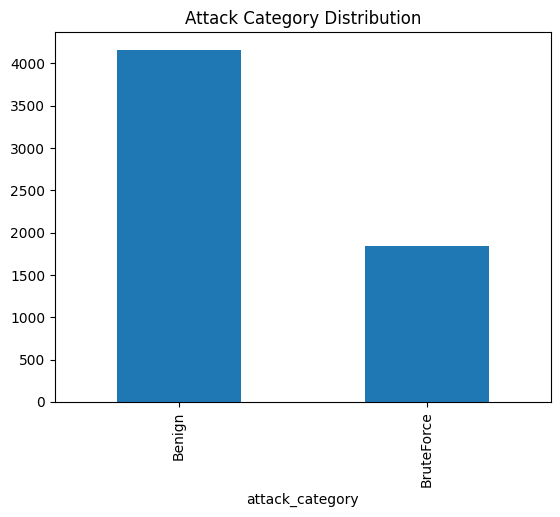

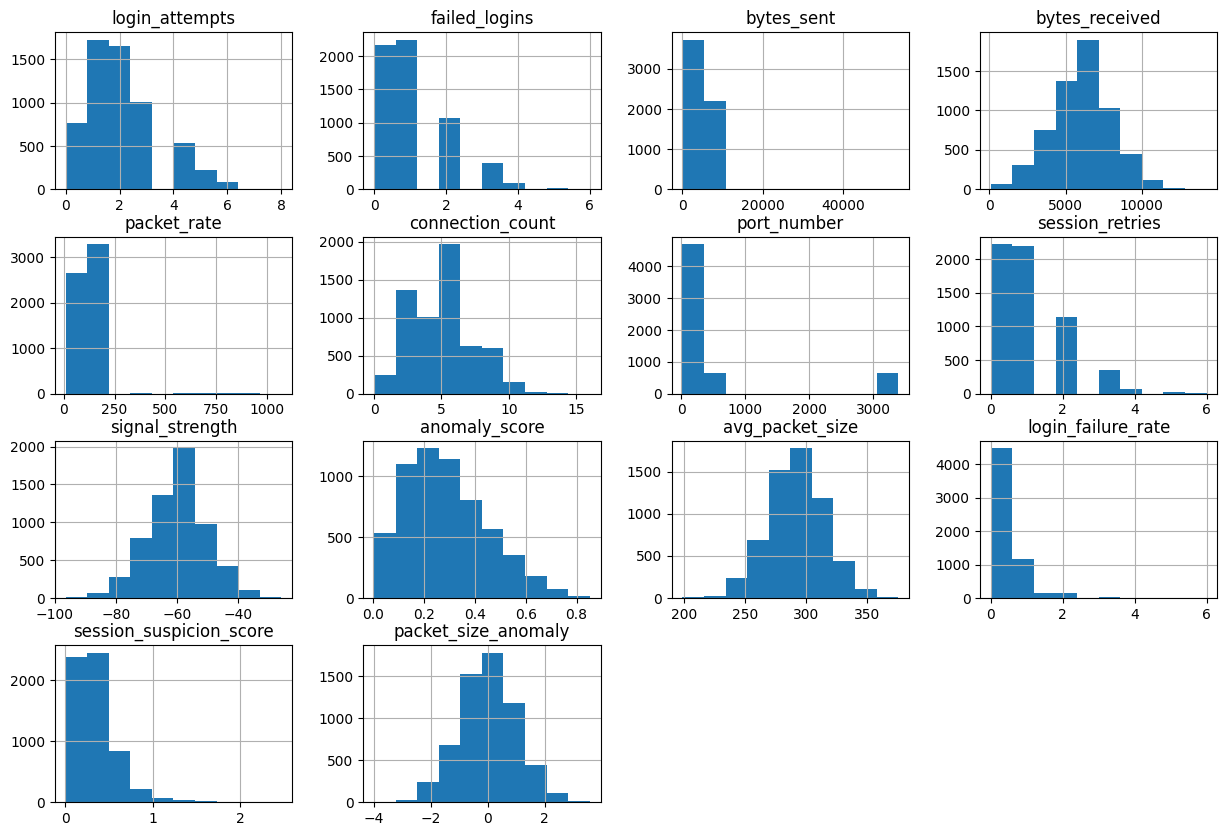

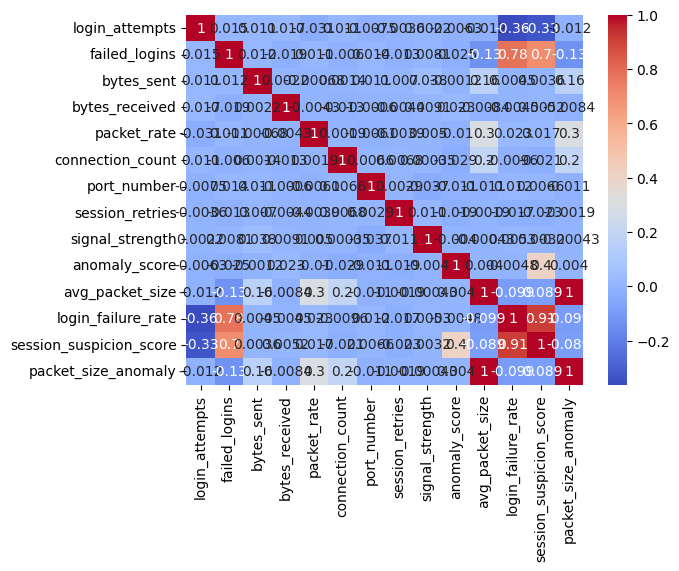

In [230]:
# Descriptive statistics
print(df_clean.describe())

# Class imbalance check
df_clean['attack_category'].value_counts().plot(kind='bar')
plt.title('Attack Category Distribution')
plt.show()

# Histograms for numeric cols
df_clean.select_dtypes(include='number').hist(figsize=(15,10))
plt.show()

# Heatmap
sns.heatmap(df_clean.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm')
plt.show()



In [231]:
# Check outliers using IQR method
from scipy import stats
import numpy as np

num_cols = df_clean.select_dtypes(include='number').columns
for col in num_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = df_clean[(df_clean[col] < Q1 - 1.5*IQR) | 
                        (df_clean[col] > Q3 + 1.5*IQR)]
    print(f"{col}: {len(outliers)} outliers")

login_attempts: 18 outliers
failed_logins: 2 outliers
bytes_sent: 102 outliers
bytes_received: 72 outliers
packet_rate: 101 outliers
connection_count: 80 outliers
port_number: 1297 outliers
session_retries: 5 outliers
signal_strength: 79 outliers
anomaly_score: 32 outliers
avg_packet_size: 49 outliers
login_failure_rate: 221 outliers
session_suspicion_score: 234 outliers
packet_size_anomaly: 49 outliers


In [232]:
Linear = LinearRegression()
Linear.fit(X_train_scaled_reg, y_train_reg)
y_pred_reg = Linear.predict(X_test_scaled_reg)
mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_reg, y_pred_reg)

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R² Score:", round(r2, 4))



Mean Absolute Error (MAE): 0.0
Mean Squared Error (MSE): 0.0
Root Mean Squared Error (RMSE): 0.0
R² Score: 1.0


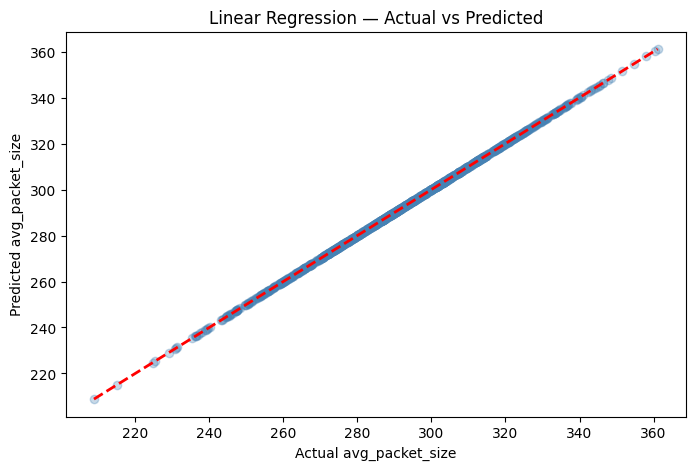

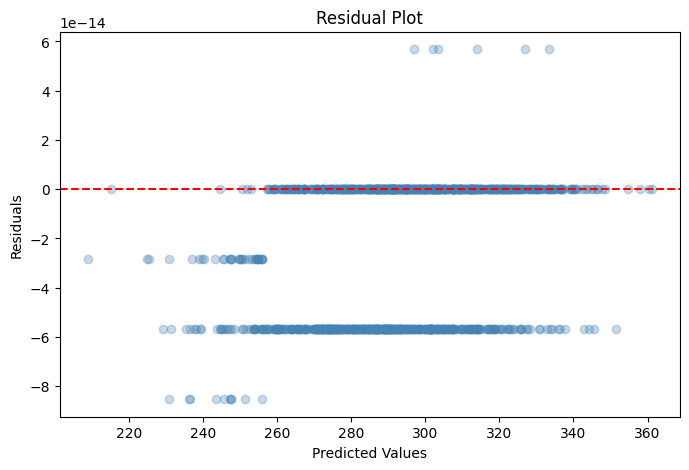

In [233]:
plt.figure(figsize=(8,5))
plt.scatter(y_test_reg, y_pred_reg, alpha=0.3, color='steelblue')
plt.plot([y_test_reg.min(), y_test_reg.max()],
         [y_test_reg.min(), y_test_reg.max()],
         'r--', linewidth=2)
plt.xlabel('Actual avg_packet_size')
plt.ylabel('Predicted avg_packet_size')
plt.title('Linear Regression — Actual vs Predicted')
plt.show()

residuals = y_test_reg - y_pred_reg
plt.figure(figsize=(8,5))
plt.scatter(y_pred_reg, residuals, alpha=0.3, color='steelblue')
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()